In [1]:
from pathlib import Path

import pandas as pd

PROCESSED_DATA_DIR = Path("../data/processed")

customers = pd.read_csv(
    PROCESSED_DATA_DIR / "customers.csv",
    parse_dates=["signup_date"],
)

products = pd.read_csv(
    PROCESSED_DATA_DIR / "products.csv",
)

orders = pd.read_csv(
    PROCESSED_DATA_DIR / "orders.csv",
    parse_dates=["order_date", "delivery_date"],
)

order_items = pd.read_csv(
    PROCESSED_DATA_DIR / "order_items.csv",
)

payments = pd.read_csv(
    PROCESSED_DATA_DIR / "payments.csv",
)

reviews = pd.read_csv(
    PROCESSED_DATA_DIR / "reviews.csv",
    parse_dates=["review_date"],
)

In [2]:
datasets = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
}

In [3]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

customers: (1000, 5)
products: (100, 6)
orders: (3200, 7)
order_items: (5376, 7)
payments: (3200, 5)
reviews: (2019, 6)


In [4]:
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
].copy()

print("Total delivered orders:", delivered_orders["order_id"].nunique())

Total delivered orders: 2627


In [5]:
order_items.columns


Index(['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_mad',
       'discount_rate', 'line_total_mad'],
      dtype='str')

In [6]:

delivered_orders.columns

Index(['order_id', 'customer_id', 'order_date', 'order_status',
       'delivery_date', 'shipping_city', 'shipping_fee_mad'],
      dtype='str')

In [7]:
delivered_sales = order_items.merge(
    delivered_orders[
        ["order_id", "order_date", "shipping_city"]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one",
)

delivered_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price_mad,discount_rate,line_total_mad,order_date,shipping_city
0,I000001,O00001,P099,3,243.24,0.10,656.75,2024-04-09,tangier
1,I000002,O00001,P014,1,3643.31,0.00,3643.31,2024-04-09,tangier
2,I000003,O00001,P071,2,2497.82,0.05,4745.86,2024-04-09,tangier
3,I000004,O00002,P075,1,2409.28,0.05,2288.82,2025-11-19,marrakech
4,I000005,O00002,P059,3,376.57,0.05,1073.22,2025-11-19,marrakech


In [8]:
total_revenue = delivered_sales["line_total_mad"].sum()

total_orders = delivered_orders["order_id"].nunique()

total_units_sold = delivered_sales["quantity"].sum()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

sales_kpis = pd.DataFrame([
    {
        "metric": "Total Revenue",
        "value": total_revenue,
        "unit": "MAD",
    },
    {
        "metric": "Delivered Orders",
        "value": total_orders,
        "unit": "Orders",
    },
    {
        "metric": "Units Sold",
        "value": total_units_sold,
        "unit": "Units",
    },
    {
        "metric": "Average Order Value",
        "value": average_order_value,
        "unit": "MAD",
    },
])

sales_kpis

,metric,value,unit
0,Total Revenue,1.278431e+07,MAD
1,Delivered Orders,2.627000e+03,Orders
2,Units Sold,7.040000e+03,Units
3,Average Order Value,4.866506e+03,MAD


In [9]:
delivered_sales["order_month"] = (
    delivered_sales["order_date"]
    .dt.to_period("M")
)

In [10]:
monthly_sales = (
    delivered_sales
    .groupby("order_month")
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
    )
    .reset_index()
)

monthly_sales["average_order_value"] = (
    monthly_sales["revenue_mad"]
    / monthly_sales["orders"]
)

monthly_sales

,order_month,revenue_mad,orders,units_sold,average_order_value
0,2024-01,552673.23,113,305,4890.913540
1,2024-02,455962.56,91,254,5010.577582
2,2024-03,566231.42,105,313,5392.680190
3,2024-04,531824.80,110,285,4834.770909
4,2024-05,500338.90,105,288,4765.132381
5,2024-06,618872.42,118,337,5244.681525
6,2024-07,503852.10,112,290,4498.679464
7,2024-08,634402.91,118,346,5376.295847
8,2024-09,430956.84,102,254,4225.067059
9,2024-10,468310.34,105,272,4460.098476


In [11]:
best_month = monthly_sales.loc[
    monthly_sales["revenue_mad"].idxmax()
]

best_month

order_month                2024-11
revenue_mad              649240.47
orders                         127
units_sold                     351
average_order_value    5112.129685
Name: 10, dtype: object

In [12]:
monthly_sales["revenue_growth_pct"] = (
    monthly_sales["revenue_mad"]
    .pct_change()
    .mul(100)
    .round(2)
)

monthly_sales

,order_month,revenue_mad,orders,units_sold,average_order_value,revenue_growth_pct
0,2024-01,552673.23,113,305,4890.913540,NaN
1,2024-02,455962.56,91,254,5010.577582,-17.50
2,2024-03,566231.42,105,313,5392.680190,24.18
3,2024-04,531824.80,110,285,4834.770909,-6.08
4,2024-05,500338.90,105,288,4765.132381,-5.92
5,2024-06,618872.42,118,337,5244.681525,23.69
6,2024-07,503852.10,112,290,4498.679464,-18.59
7,2024-08,634402.91,118,346,5376.295847,25.91
8,2024-09,430956.84,102,254,4225.067059,-32.07
9,2024-10,468310.34,105,272,4460.098476,8.67


In [13]:
# Inspect product columns before joining
print(products.columns.tolist())
print(order_items.columns.tolist())

['product_id', 'product_name', 'category', 'unit_price_mad', 'cost_price_mad', 'stock_status']
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_mad', 'discount_rate', 'line_total_mad']


In [14]:
product_sales = delivered_sales.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

product_sales.sample()

,order_item_id,order_id,product_id,quantity,unit_price_mad_x,discount_rate,line_total_mad,order_date,shipping_city,order_month,product_name,category,unit_price_mad_y,cost_price_mad,stock_status,_merge
896,I001085,O00652,P060,1,1251.94,0.2,1001.55,2025-02-13,meknes,2025-02,Lamp 4,home,1251.94,989.98,In Stock,both


In [15]:
product_sales["_merge"].value_counts()

_merge
both          4395
left_only        0
right_only       0
Name: count, dtype: int64

In [16]:
#Analyze product performance
product_performance = (
    product_sales
    .groupby(["product_id", "category"])
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_id", "nunique"),
    )
    .reset_index()
)

product_performance["average_selling_price_mad"] = (
    product_performance["revenue_mad"]
    / product_performance["units_sold"]
)

product_performance = product_performance.sort_values(
    "revenue_mad",
    ascending=False,
)

product_performance.head(10)

,product_id,category,revenue_mad,units_sold,orders,average_selling_price_mad
24,P025,computers,543941.51,91,56,5977.379231
33,P034,computers,384071.82,59,39,6509.691864
39,P040,computers,365124.35,71,44,5142.596479
35,P036,computers,341614.81,68,44,5023.747206
22,P023,computers,338732.24,81,51,4181.879506
16,P017,electronics,331802.20,99,57,3351.537374
21,P022,computers,316167.99,58,34,5451.172241
4,P005,electronics,296288.20,93,55,3185.894624
26,P027,computers,292473.43,69,43,4238.745362
2,P003,electronics,290334.20,79,52,3675.116456


In [17]:
# Analyze category performance
category_performance = (
    product_sales
    .groupby("category")
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        units_sold=("quantity", "sum"),
        orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
    )
    .reset_index()
    .sort_values("revenue_mad", ascending=False)
)

category_performance

,category,revenue_mad,units_sold,orders,unique_products
1,computers,4942738.85,1355,764,20
2,electronics,3927222.06,1407,796,20
3,gaming,2739090.95,1484,833,20
4,home,973437.25,1487,821,20
0,accessories,201821.59,1307,752,20


In [18]:
total_revenue = category_performance["revenue_mad"].sum()

category_performance["revenue_share_pct"] = (
    category_performance["revenue_mad"]
    / total_revenue
    * 100
).round(2)

category_performance

,category,revenue_mad,units_sold,orders,unique_products,revenue_share_pct
1,computers,4942738.85,1355,764,20,38.66
2,electronics,3927222.06,1407,796,20,30.72
3,gaming,2739090.95,1484,833,20,21.43
4,home,973437.25,1487,821,20,7.61
0,accessories,201821.59,1307,752,20,1.58


In [19]:
assert "cost_price_mad" in product_sales.columns
assert "quantity" in product_sales.columns

In [20]:
product_sales["estimated_cost_mad"] = (
    product_sales["quantity"]
    * product_sales["cost_price_mad"]
)

product_sales["estimated_gross_profit_mad"] = (
    product_sales["line_total_mad"]
    - product_sales["estimated_cost_mad"]
)

In [21]:
product_profitability = (
    product_sales
    .groupby(["product_id", "category"])
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        cost_mad=("estimated_cost_mad", "sum"),
        gross_profit_mad=(
            "estimated_gross_profit_mad",
            "sum",
        ),
        units_sold=("quantity", "sum"),
    )
    .reset_index()
)

product_profitability["gross_margin_pct"] = (
    product_profitability["gross_profit_mad"]
    / product_profitability["revenue_mad"]
    * 100
).round(2)

product_profitability = product_profitability.sort_values(
    "gross_profit_mad",
    ascending=False,
)

product_profitability.head(10)

,product_id,category,revenue_mad,cost_mad,gross_profit_mad,units_sold,gross_margin_pct
24,P025,computers,543941.51,356229.51,187712.00,91,34.51
16,P017,electronics,331802.20,215110.17,116692.03,99,35.17
22,P023,computers,338732.24,234830.34,103901.90,81,30.67
39,P040,computers,365124.35,263452.60,101671.75,71,27.85
14,P015,electronics,289321.61,198602.40,90719.21,83,31.36
32,P033,computers,229886.25,139635.36,90250.89,72,39.26
35,P036,computers,341614.81,253368.00,88246.81,68,25.83
1,P002,electronics,219200.43,136302.39,82898.04,63,37.82
79,P080,gaming,202210.08,120666.18,81543.90,79,40.33
23,P024,computers,233754.91,154009.02,79745.89,66,34.12


In [22]:
products_with_sales = product_performance[
    ["product_id", "units_sold", "revenue_mad"]
]

product_sales_coverage = products.merge(
    products_with_sales,
    on="product_id",
    how="left",
    validate="one_to_one",
)

product_sales_coverage[
    ["units_sold", "revenue_mad"]
] = product_sales_coverage[
    ["units_sold", "revenue_mad"]
].fillna(0)

products_without_sales = product_sales_coverage.loc[
    product_sales_coverage["units_sold"].eq(0)
]

products_without_sales.head()

,product_id,product_name,category,unit_price_mad,cost_price_mad,stock_status,units_sold,revenue_mad


## 4. Geographic Performance Analysis

In [23]:
city_performance = (
    delivered_sales
    .groupby("shipping_city")
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
    )
    .reset_index()
)

city_performance["average_order_value_mad"] = (
    city_performance["revenue_mad"]
    / city_performance["orders"]
)

city_performance = city_performance.sort_values(
    "revenue_mad",
    ascending=False,
).reset_index(drop=True)

city_performance

,shipping_city,revenue_mad,orders,units_sold,average_order_value_mad
0,casablanca,2983973.57,606,1620,4924.048795
1,marrakech,1902172.73,382,1041,4979.509764
2,rabat,1340689.52,284,767,4720.737746
3,tangier,1160065.07,252,666,4603.432817
4,fes,1126717.93,232,639,4856.542802
5,agadir,986092.51,188,521,5245.172926
6,meknes,724358.53,148,386,4894.314392
7,tetouan,659212.47,123,341,5359.450976
8,kenitra,613984.52,150,359,4093.230133
9,oujda,580665.95,129,324,4501.286434


In [24]:
total_revenue = city_performance["revenue_mad"].sum()

city_performance["revenue_share_pct"] = (
    city_performance["revenue_mad"]
    / total_revenue
    * 100
).round(2)

city_performance

,shipping_city,revenue_mad,orders,units_sold,average_order_value_mad,revenue_share_pct
0,casablanca,2983973.57,606,1620,4924.048795,23.34
1,marrakech,1902172.73,382,1041,4979.509764,14.88
2,rabat,1340689.52,284,767,4720.737746,10.49
3,tangier,1160065.07,252,666,4603.432817,9.07
4,fes,1126717.93,232,639,4856.542802,8.81
5,agadir,986092.51,188,521,5245.172926,7.71
6,meknes,724358.53,148,386,4894.314392,5.67
7,tetouan,659212.47,123,341,5359.450976,5.16
8,kenitra,613984.52,150,359,4093.230133,4.80
9,oujda,580665.95,129,324,4501.286434,4.54


In [25]:
city_customers = (
    delivered_orders
    .groupby("shipping_city")
    .agg(
        unique_customers=("customer_id", "nunique"),
    )
    .reset_index()
)

city_performance = city_performance.merge(
    city_customers,
    on="shipping_city",
    how="left",
    validate="one_to_one",
)

city_performance

,shipping_city,revenue_mad,orders,units_sold,average_order_value_mad,revenue_share_pct,unique_customers
0,casablanca,2983973.57,606,1620,4924.048795,23.34,221
1,marrakech,1902172.73,382,1041,4979.509764,14.88,133
2,rabat,1340689.52,284,767,4720.737746,10.49,106
3,tangier,1160065.07,252,666,4603.432817,9.07,87
4,fes,1126717.93,232,639,4856.542802,8.81,78
5,agadir,986092.51,188,521,5245.172926,7.71,71
6,meknes,724358.53,148,386,4894.314392,5.67,50
7,tetouan,659212.47,123,341,5359.450976,5.16,44
8,kenitra,613984.52,150,359,4093.230133,4.80,55
9,oujda,580665.95,129,324,4501.286434,4.54,46


In [26]:
customer_sales = delivered_sales.merge(
    delivered_orders[["order_id", "customer_id"]],
    on="order_id",
    how="left",
    validate="many_to_one",
)

customer_sales = customer_sales.merge(
    customers[["customer_id", "customer_segment", "customer_age"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

customer_sales.head()

,order_item_id,order_id,product_id,quantity,unit_price_mad,discount_rate,line_total_mad,order_date,shipping_city,order_month,customer_id,customer_segment,customer_age
0,I000001,O00001,P099,3,243.24,0.10,656.75,2024-04-09,tangier,2024-04,C0713,regular,28.0
1,I000002,O00001,P014,1,3643.31,0.00,3643.31,2024-04-09,tangier,2024-04,C0713,regular,28.0
2,I000003,O00001,P071,2,2497.82,0.05,4745.86,2024-04-09,tangier,2024-04,C0713,regular,28.0
3,I000004,O00002,P075,1,2409.28,0.05,2288.82,2025-11-19,marrakech,2025-11,C0942,regular,21.0
4,I000005,O00002,P059,3,376.57,0.05,1073.22,2025-11-19,marrakech,2025-11,C0942,regular,21.0


In [27]:
segment_performance = (
    customer_sales
    .groupby("customer_segment")
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
        units_sold=("quantity", "sum"),
    )
    .reset_index()
)

segment_performance["average_order_value_mad"] = (
    segment_performance["revenue_mad"]
    / segment_performance["orders"]
)

segment_performance["revenue_share_pct"] = (
    segment_performance["revenue_mad"]
    / segment_performance["revenue_mad"].sum()
    * 100
).round(2)

segment_performance.sort_values(
    "revenue_mad",
    ascending=False,
)

,customer_segment,revenue_mad,orders,customers,units_sold,average_order_value_mad,revenue_share_pct
2,regular,7958158.70,1631,590,4319,4879.312508,62.25
0,new,2494091.59,515,182,1409,4842.896291,19.51
1,premium,2332060.41,481,165,1312,4848.358441,18.24


In [28]:
customer_performance = (
    customer_sales
    .groupby(["customer_id", "customer_segment", ])
    .agg(
        total_revenue_mad=("line_total_mad", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
    )
    .reset_index()
)

customer_performance["average_order_value_mad"] = (
    customer_performance["total_revenue_mad"]
    / customer_performance["total_orders"]
)

customer_performance = customer_performance.sort_values(
    "total_revenue_mad",
    ascending=False,
)

customer_performance.head(10)

,customer_id,customer_segment,total_revenue_mad,total_orders,total_units,average_order_value_mad
293,C0307,regular,74586.92,9,35,8287.435556
783,C0837,regular,56182.77,5,24,11236.554000
432,C0457,regular,55570.17,6,22,9261.695000
673,C0715,regular,51811.29,7,24,7401.612857
225,C0235,premium,50428.85,6,21,8404.808333
770,C0823,new,49258.14,3,14,16419.380000
740,C0788,regular,48492.59,7,25,6927.512857
567,C0607,regular,47937.14,4,16,11984.285000
578,C0618,premium,47000.26,8,23,5875.032500
277,C0290,regular,46817.88,2,14,23408.940000


In [29]:
total_customer_revenue = customer_performance[
    "total_revenue_mad"
].sum()

top_10_customer_revenue = customer_performance.head(10)[
    "total_revenue_mad"
].sum()

top_10_revenue_share_pct = (
    top_10_customer_revenue
    / total_customer_revenue
    * 100
)

print(f"Top 10 customers' revenue share: {top_10_revenue_share_pct:.2f}%")

Top 10 customers' revenue share: 4.13%


## 6. Order and Payment Performance

In [30]:
order_status_performance = (
    orders
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
    )
    .reset_index()
)

order_status_performance["percentage"] = (
    order_status_performance["total_orders"]
    / order_status_performance["total_orders"].sum()
    * 100
).round(2)

order_status_performance.sort_values(
    "total_orders",
    ascending=False,
)

,order_status,total_orders,percentage
1,delivered,2627,82.09
0,cancelled,256,8.00
3,returned,167,5.22
2,processing,150,4.69


In [31]:
total_orders = orders["order_id"].nunique()

cancelled_orders = orders.loc[
    orders["order_status"].eq("cancelled"),
    "order_id",
].nunique()

returned_orders = orders.loc[
    orders["order_status"].eq("returned"),
    "order_id",
].nunique()

cancellation_rate = (
    cancelled_orders / total_orders * 100
    if total_orders else 0
)

return_rate = (
    returned_orders / total_orders * 100
    if total_orders else 0
)

print(f"Total orders: {total_orders}")
print(f"Cancelled orders: {cancelled_orders}")
print(f"Cancellation rate: {cancellation_rate:.2f}%")
print(f"Returned orders: {returned_orders}")
print(f"Return rate: {return_rate:.2f}%")

Total orders: 3200
Cancelled orders: 256
Cancellation rate: 8.00%
Returned orders: 167
Return rate: 5.22%


In [32]:
payment_method_performance = (
    payments
    .groupby("payment_method")
    .agg(
        transactions=("order_id", "nunique"),
        payment_amount_mad=("payment_amount_mad", "sum"),
    )
    .reset_index()
    .sort_values("transactions", ascending=False)
)

payment_method_performance["transaction_share_pct"] = (
    payment_method_performance["transactions"]
    / payment_method_performance["transactions"].sum()
    * 100
).round(2)

payment_method_performance

,payment_method,transactions,payment_amount_mad,transaction_share_pct
2,cash on delivery,1343,6710013.84,41.97
1,card,1221,6084931.58,38.16
0,bank transfer,367,1709961.20,11.47
3,wallet,269,1296494.97,8.41


In [33]:
payment_status_performance = (
    payments
    .groupby("payment_status")
    .agg(
        transactions=("order_id", "nunique"),
        payment_amount_mad=("payment_amount_mad", "sum"),
    )
    .reset_index()
)

payment_status_performance["percentage"] = (
    payment_status_performance["transactions"]
    / payment_status_performance["transactions"].sum()
    * 100
).round(2)

payment_status_performance

,payment_status,transactions,payment_amount_mad,percentage
0,failed,68,308997.50,2.12
1,paid,2965,14621630.44,92.66
2,refunded,167,870773.65,5.22


In [34]:
total_payments = payments["order_id"].nunique()

failed_payments = payments.loc[
    payments["payment_status"].eq("failed"),
    "order_id",
].nunique()

payment_failure_rate = (
    failed_payments / total_payments * 100
    if total_payments else 0
)

print(f"Payment failure rate: {payment_failure_rate:.2f}%")

Payment failure rate: 2.12%


In [35]:
delivery_data = delivered_orders.loc[
    delivered_orders["order_date"].notna()
    & delivered_orders["delivery_date"].notna()
].copy()

delivery_data["delivery_days"] = (
    delivery_data["delivery_date"]
    - delivery_data["order_date"]
).dt.total_seconds() / 86400

delivery_data[["order_id", "order_date", "delivery_date", "delivery_days"]].head()

,order_id,order_date,delivery_date,delivery_days
0,O00001,2024-04-09,2024-04-13,4.0
1,O00002,2025-11-19,2025-11-23,4.0
2,O00003,2024-12-13,2024-12-20,7.0
3,O00004,2024-08-21,2024-08-24,3.0
4,O00005,2024-11-22,2024-11-23,1.0


In [36]:
invalid_delivery_count = delivery_data[
    "delivery_days"
].lt(0).sum()

print(f"Invalid negative delivery durations: {invalid_delivery_count}")

Invalid negative delivery durations: 0


In [37]:
delivery_kpis = pd.DataFrame([
    {
        "metric": "Average delivery time",
        "value": delivery_data["delivery_days"].mean(),
        "unit": "Days",
    },
    {
        "metric": "Median delivery time",
        "value": delivery_data["delivery_days"].median(),
        "unit": "Days",
    },
    {
        "metric": "Minimum delivery time",
        "value": delivery_data["delivery_days"].min(),
        "unit": "Days",
    },
    {
        "metric": "Maximum delivery time",
        "value": delivery_data["delivery_days"].max(),
        "unit": "Days",
    },
])

delivery_kpis.round(2)

,metric,value,unit
0,Average delivery time,3.48,Days
1,Median delivery time,3.00,Days
2,Minimum delivery time,1.00,Days
3,Maximum delivery time,11.00,Days


In [38]:
delivery_by_city = (
    delivery_data
    .groupby("shipping_city")
    .agg(
        delivered_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median"),
    )
    .reset_index()
    .sort_values("average_delivery_days", ascending=False)
)

delivery_by_city.round(2)

,shipping_city,delivered_orders,average_delivery_days,median_delivery_days
7,oujda,129,3.72,4.0
4,kenitra,150,3.70,3.0
6,meknes,148,3.64,3.5
11,tetouan,123,3.60,3.0
0,agadir,188,3.51,3.0
1,casablanca,606,3.49,3.0
5,marrakech,382,3.45,3.0
10,tangier,252,3.42,3.0
8,rabat,284,3.40,3.0
3,fes,232,3.38,3.0


## 7. Customer Reviews and Satisfaction Analysis

In [39]:
# Display the first records
reviews.head()

# Dataset dimensions
print("Reviews shape:", reviews.shape)

# Data types and missing values
reviews.info()

# Statistical summary
reviews.describe(include="all")

Reviews shape: (2019, 6)
<class 'pandas.DataFrame'>
RangeIndex: 2019 entries, 0 to 2018
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   review_id       2019 non-null   str           
 1   order_id        2019 non-null   str           
 2   customer_id     2019 non-null   str           
 3   rating          2019 non-null   int64         
 4   review_date     2019 non-null   datetime64[us]
 5   review_comment  2004 non-null   str           
dtypes: datetime64[us](1), int64(1), str(4)
memory usage: 94.8 KB


,review_id,order_id,customer_id,rating,review_date,review_comment
count,2019,2019,2019,2019.000000,2019,2004
unique,2019,2019,868,NaN,NaN,6
top,R00001,O00001,C0307,NaN,NaN,Packaging could improve
freq,1,1,8,NaN,NaN,359
mean,NaN,NaN,NaN,3.909856,2025-01-10 00:36:22.466567,NaN
min,NaN,NaN,NaN,1.000000,2024-01-02 00:00:00,NaN
25%,NaN,NaN,NaN,3.000000,2024-07-20 12:00:00,NaN
50%,NaN,NaN,NaN,4.000000,2025-01-14 00:00:00,NaN
75%,NaN,NaN,NaN,5.000000,2025-07-05 12:00:00,NaN
max,NaN,NaN,NaN,5.000000,2026-01-13 00:00:00,NaN


In [40]:
reviews["rating"].value_counts(dropna=False).sort_index()

rating
1     10
2    134
3    505
4    749
5    621
Name: count, dtype: int64

In [41]:
invalid_ratings = reviews.loc[
    reviews["rating"].notna()
    & ~reviews["rating"].between(1, 5)
]

print("Invalid ratings:", len(invalid_ratings))

Invalid ratings: 0


In [42]:
total_reviews = len(reviews)

valid_ratings = reviews["rating"].dropna()

average_rating = valid_ratings.mean()
median_rating = valid_ratings.median()

five_star_reviews = valid_ratings.eq(5).sum()
one_star_reviews = valid_ratings.eq(1).sum()

positive_reviews = valid_ratings.ge(4).sum()
negative_reviews = valid_ratings.le(2).sum()

valid_review_count = len(valid_ratings)

satisfaction_rate = (
    positive_reviews / valid_review_count * 100
    if valid_review_count else 0
)

dissatisfaction_rate = (
    negative_reviews / valid_review_count * 100
    if valid_review_count else 0
)

review_kpis = pd.DataFrame([
    {
        "metric": "Total reviews",
        "value": total_reviews,
        "unit": "Reviews",
    },
    {
        "metric": "Valid ratings",
        "value": valid_review_count,
        "unit": "Ratings",
    },
    {
        "metric": "Average rating",
        "value": average_rating,
        "unit": "Stars",
    },
    {
        "metric": "Median rating",
        "value": median_rating,
        "unit": "Stars",
    },
    {
        "metric": "Satisfaction rate",
        "value": satisfaction_rate,
        "unit": "%",
    },
    {
        "metric": "Dissatisfaction rate",
        "value": dissatisfaction_rate,
        "unit": "%",
    },
])

review_kpis.round(2)

,metric,value,unit
0,Total reviews,2019.00,Reviews
1,Valid ratings,2019.00,Ratings
2,Average rating,3.91,Stars
3,Median rating,4.00,Stars
4,Satisfaction rate,67.86,%
5,Dissatisfaction rate,7.13,%


In [43]:
rating_distribution = (
    reviews["rating"]
    .value_counts()
    .sort_index()
    .rename_axis("rating")
    .reset_index(name="review_count")
)

rating_distribution["percentage"] = (
    rating_distribution["review_count"]
    / rating_distribution["review_count"].sum()
    * 100
).round(2)

rating_distribution

,rating,review_count,percentage
0,1,10,0.50
1,2,134,6.64
2,3,505,25.01
3,4,749,37.10
4,5,621,30.76


In [44]:
reviews_with_orders = reviews.merge(
    orders[["order_id", "shipping_city"]],
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

reviews_with_orders["_merge"].value_counts()

_merge
both          2019
left_only        0
right_only       0
Name: count, dtype: int64

In [45]:
city_satisfaction = (
    reviews_with_orders
    .dropna(subset=["rating"])
    .groupby("shipping_city")
    .agg(
        average_rating=("rating", "mean"),
        median_rating=("rating", "median"),
        total_reviews=("rating", "count"),
    )
    .reset_index()
)

city_satisfaction["average_rating"] = (
    city_satisfaction["average_rating"].round(2)
)

city_satisfaction = city_satisfaction.sort_values(
    "average_rating",
    ascending=False,
)

city_satisfaction

,shipping_city,average_rating,median_rating,total_reviews
9,safi,4.02,4.0,47
10,tangier,3.95,4.0,197
6,meknes,3.94,4.0,109
5,marrakech,3.93,4.0,292
11,tetouan,3.93,4.0,90
7,oujda,3.92,4.0,98
1,casablanca,3.90,4.0,458
3,fes,3.89,4.0,171
4,kenitra,3.88,4.0,127
0,agadir,3.88,4.0,156


In [46]:
reviews_with_customers = reviews.merge(
    customers[["customer_id", "customer_segment"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

reviews_with_customers["_merge"].value_counts()

_merge
both          2019
left_only        0
right_only       0
Name: count, dtype: int64

In [47]:
segment_satisfaction = (
    reviews_with_customers
    .dropna(subset=["rating"])
    .groupby("customer_segment")
    .agg(
        average_rating=("rating", "mean"),
        median_rating=("rating", "median"),
        total_reviews=("rating", "count"),
    )
    .reset_index()
)

segment_satisfaction["average_rating"] = (
    segment_satisfaction["average_rating"].round(2)
)

segment_satisfaction.sort_values(
    "average_rating",
    ascending=False,
)

,customer_segment,average_rating,median_rating,total_reviews
0,new,3.92,4.0,396
2,regular,3.92,4.0,1249
1,premium,3.87,4.0,374


In [48]:
reviews_with_products = reviews.merge(
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="inner",
    validate="one_to_many",
)

reviews_with_products = reviews_with_products.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)

reviews_with_products.head()

,review_id,order_id,customer_id,rating,review_date,review_comment,product_id,category
0,R00001,O00001,C0713,4,2024-04-14,Satisfied,P099,accessories
1,R00001,O00001,C0713,4,2024-04-14,Satisfied,P014,electronics
2,R00001,O00001,C0713,4,2024-04-14,Satisfied,P071,gaming
3,R00002,O00002,C0942,4,2025-11-28,Not as expected,P075,gaming
4,R00002,O00002,C0942,4,2025-11-28,Not as expected,P059,home


In [49]:
product_satisfaction = (
    reviews_with_products
    .dropna(subset=["rating"])
    .groupby("product_id")
    .agg(
        average_rating=("rating", "mean"),
        total_reviews=("rating", "count"),
        category=("category", "first"),
    )
    .reset_index()
)

product_satisfaction["average_rating"] = (
    product_satisfaction["average_rating"].round(2)
)

# Require at least 5 associated reviews for a more reliable comparison
product_satisfaction_filtered = product_satisfaction.loc[
    product_satisfaction["total_reviews"] >= 5
].copy()

# Highest-rated products
top_rated_products = product_satisfaction_filtered.sort_values(
    ["average_rating", "total_reviews"],
    ascending=[False, False],
)

# Lowest-rated products
lowest_rated_products = product_satisfaction_filtered.sort_values(
    ["average_rating", "total_reviews"],
    ascending=[True, False],
)

print("Top-rated products")
display(top_rated_products.head(10))

print("Lowest-rated products")
display(lowest_rated_products.head(10))

Top-rated products


,product_id,average_rating,total_reviews,category
60,P061,4.37,35,gaming
73,P074,4.25,32,gaming
9,P010,4.24,29,electronics
36,P037,4.22,23,computers
14,P015,4.16,32,electronics
51,P052,4.14,35,home
63,P064,4.14,28,gaming
92,P093,4.14,22,accessories
8,P009,4.12,33,electronics
72,P073,4.12,33,gaming


Lowest-rated products


,product_id,average_rating,total_reviews,category
55,P056,3.55,38,home
16,P017,3.61,44,electronics
68,P069,3.63,19,gaming
39,P040,3.65,31,computers
20,P021,3.67,30,computers
33,P034,3.68,31,computers
78,P079,3.69,36,gaming
32,P033,3.69,29,computers
42,P043,3.71,31,home
37,P038,3.71,28,computers


In [50]:
# Check the actual comment column name first
reviews.columns.tolist()

['review_id',
 'order_id',
 'customer_id',
 'rating',
 'review_date',
 'review_comment']

In [51]:
total_reviews = len(reviews)

reviews_with_comments = reviews["review_comment"].notna().sum()

reviews_without_comments = total_reviews - reviews_with_comments

comment_completion_rate = (
    reviews_with_comments / total_reviews * 100
    if total_reviews else 0
)

comment_analysis = pd.DataFrame([
    {
        "metric": "Total reviews",
        "value": total_reviews,
    },
    {
        "metric": "Reviews with comments",
        "value": reviews_with_comments,
    },
    {
        "metric": "Reviews without comments",
        "value": reviews_without_comments,
    },
    {
        "metric": "Comment completion rate",
        "value": round(comment_completion_rate, 2),
    },
])

comment_analysis

,metric,value
0,Total reviews,2019.00
1,Reviews with comments,2004.00
2,Reviews without comments,15.00
3,Comment completion rate,99.26


In [52]:
monthly_satisfaction = (
    reviews
    .dropna(subset=["rating", "review_date"])
    .assign(
        review_month=lambda df: df["review_date"].dt.to_period("M")
    )
    .groupby("review_month")
    .agg(
        average_rating=("rating", "mean"),
        total_reviews=("rating", "count"),
    )
    .reset_index()
    .sort_values("review_month")
)

monthly_satisfaction["average_rating"] = (
    monthly_satisfaction["average_rating"].round(2)
)

monthly_satisfaction


,review_month,average_rating,total_reviews
0,2024-01,3.86,74
1,2024-02,3.91,68
2,2024-03,3.86,69
3,2024-04,3.89,85
4,2024-05,4.08,79
5,2024-06,3.77,77
6,2024-07,3.77,94
7,2024-08,3.79,89
8,2024-09,3.95,85
9,2024-10,3.84,73


In [53]:
satisfaction_summary = {
    "total_reviews": total_reviews,
    "average_rating": round(average_rating, 2),
    "median_rating": round(median_rating, 2),
    "satisfaction_rate_pct": round(satisfaction_rate, 2),
    "dissatisfaction_rate_pct": round(dissatisfaction_rate, 2),
    "five_star_reviews": int(five_star_reviews),
    "one_star_reviews": int(one_star_reviews),
}

pd.DataFrame(
    [satisfaction_summary]
).T.rename(columns={0: "value"})

,value
total_reviews,2019.00
average_rating,3.91
median_rating,4.00
satisfaction_rate_pct,67.86
dissatisfaction_rate_pct,7.13
five_star_reviews,621.00
one_star_reviews,10.00


## 8. Testing Reusable Analytics Functions

In [54]:
from morocco_retail_intelligence.analysis.sales import (
    calculate_sales_kpis,
    calculate_monthly_sales,
)

from morocco_retail_intelligence.analysis.products import (
    calculate_product_performance,
    calculate_category_performance,
    calculate_product_profitability,
)

from morocco_retail_intelligence.analysis.customers import (
    calculate_segment_performance,
    calculate_customer_performance,
)

from morocco_retail_intelligence.analysis.operations import (
    calculate_order_status_performance,
    calculate_cancellation_and_return_rates,
    calculate_payment_method_performance,
    calculate_payment_status_performance,
    calculate_payment_failure_rate,
    calculate_delivery_performance,
    calculate_delivery_by_city,
)

from morocco_retail_intelligence.analysis.reviews import (
    calculate_review_kpis,
    calculate_rating_distribution,
    calculate_satisfaction_by_city,
    calculate_satisfaction_by_segment,
    calculate_monthly_satisfaction,
    calculate_comment_statistics,
)

In [55]:
# Sales
sales_kpis = calculate_sales_kpis(orders, order_items)
monthly_sales = calculate_monthly_sales(orders, order_items)

# Products
product_performance = calculate_product_performance(
    orders, order_items, products
)
category_performance = calculate_category_performance(
    orders, order_items, products
)
product_profitability = calculate_product_profitability(
    orders, order_items, products
)

# Customers
segment_performance = calculate_segment_performance(
    orders, order_items, customers
)
customer_performance = calculate_customer_performance(
    orders, order_items, customers
)

# Operations
order_status = calculate_order_status_performance(orders)
order_rates = calculate_cancellation_and_return_rates(orders)

payment_methods = calculate_payment_method_performance(payments)
payment_status = calculate_payment_status_performance(payments)
payment_failure_rate = calculate_payment_failure_rate(payments)

delivery_data, delivery_summary = calculate_delivery_performance(orders)
delivery_by_city = calculate_delivery_by_city(delivery_data)

# Reviews
review_kpis = calculate_review_kpis(reviews)
rating_distribution = calculate_rating_distribution(reviews)

satisfaction_by_city = calculate_satisfaction_by_city(
    reviews, orders
)
satisfaction_by_segment = calculate_satisfaction_by_segment(
    reviews, customers
)
monthly_satisfaction = calculate_monthly_satisfaction(reviews)

comment_statistics = calculate_comment_statistics(reviews)

In [56]:
print("Sales KPIs")
display(pd.DataFrame([sales_kpis]))

print("Category performance")
display(category_performance)

print("Customer segments")
display(segment_performance)

print("Order status")
display(order_status)

print("Delivery summary")
display(delivery_summary)

print("Review KPIs")
display(pd.DataFrame([review_kpis]))

Sales KPIs


,total_revenue_mad,total_delivered_orders,total_units_sold,average_order_value_mad
0,12784310.7,2627,7040,4866.505786


Category performance


,category,revenue_mad,units_sold,orders,unique_products,revenue_share_pct
1,computers,4942738.85,1355,764,20,38.662537
2,electronics,3927222.06,1407,796,20,30.719076
3,gaming,2739090.95,1484,833,20,21.425410
4,home,973437.25,1487,821,20,7.614312
0,accessories,201821.59,1307,752,20,1.578666


Customer segments


,customer_segment,revenue_mad,orders,customers,units_sold,average_order_value_mad,revenue_share_pct
2,regular,7958158.70,1631,590,4319,4879.312508,62.249416
0,new,2494091.59,515,182,1409,4842.896291,19.509003
1,premium,2332060.41,481,165,1312,4848.358441,18.241581


... (2 outputs left out)

Delivery summary


,metric,value,unit
0,Average delivery time,3.481919,Days
1,Median delivery time,3.000000,Days
2,Minimum delivery time,1.000000,Days
3,Maximum delivery time,11.000000,Days


Review KPIs


,total_reviews,valid_ratings,average_rating,median_rating,satisfaction_rate_pct,dissatisfaction_rate_pct,five_star_reviews,one_star_reviews
0,2019,2019,3.909856,4.0,67.855374,7.132244,621,10


## 9. Business Intelligence Visualizations


In [57]:
from pathlib import Path

from morocco_retail_intelligence.visualization.charts import (
    plot_monthly_revenue,
    plot_category_revenue,
    plot_top_cities,
    plot_customer_segments,
    plot_payment_status,
    plot_delivery_distribution,
    plot_rating_distribution,
    plot_monthly_satisfaction,
)

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [58]:
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
].copy()

delivered_sales = order_items.merge(
    delivered_orders[
        ["order_id", "order_date", "shipping_city"]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one",
)

city_performance = (
    delivered_sales
    .groupby("shipping_city")
    .agg(
        revenue_mad=("line_total_mad", "sum"),
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
    )
    .reset_index()
)

city_performance["average_order_value_mad"] = (
    city_performance["revenue_mad"]
    / city_performance["orders"]
)

city_performance["revenue_share_pct"] = (
    city_performance["revenue_mad"]
    / city_performance["revenue_mad"].sum()
    * 100
).round(2)

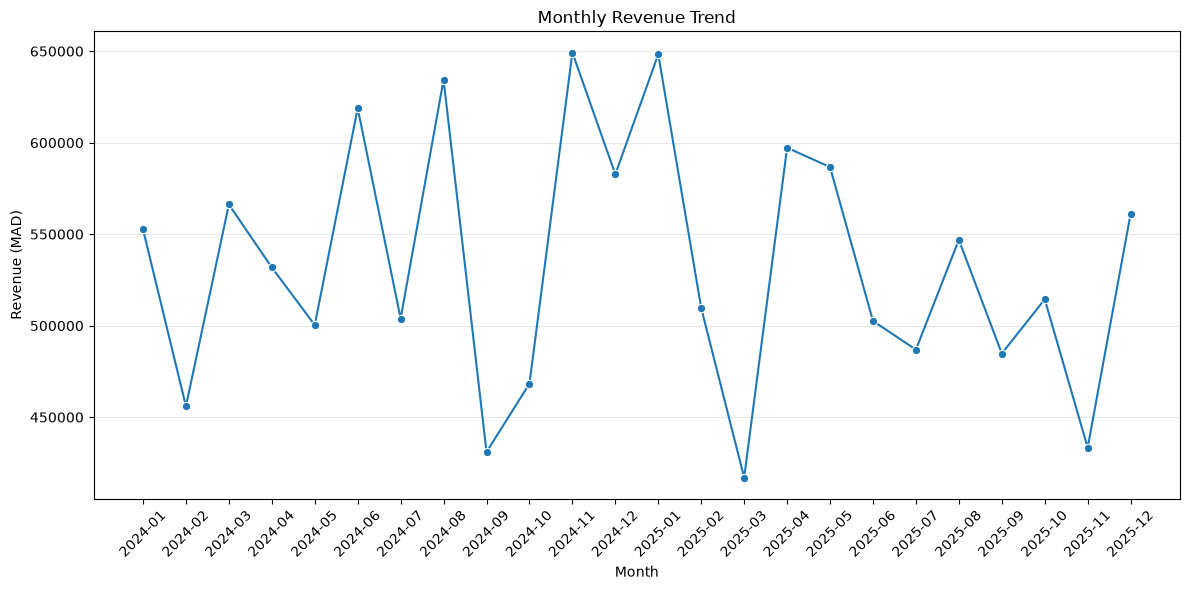

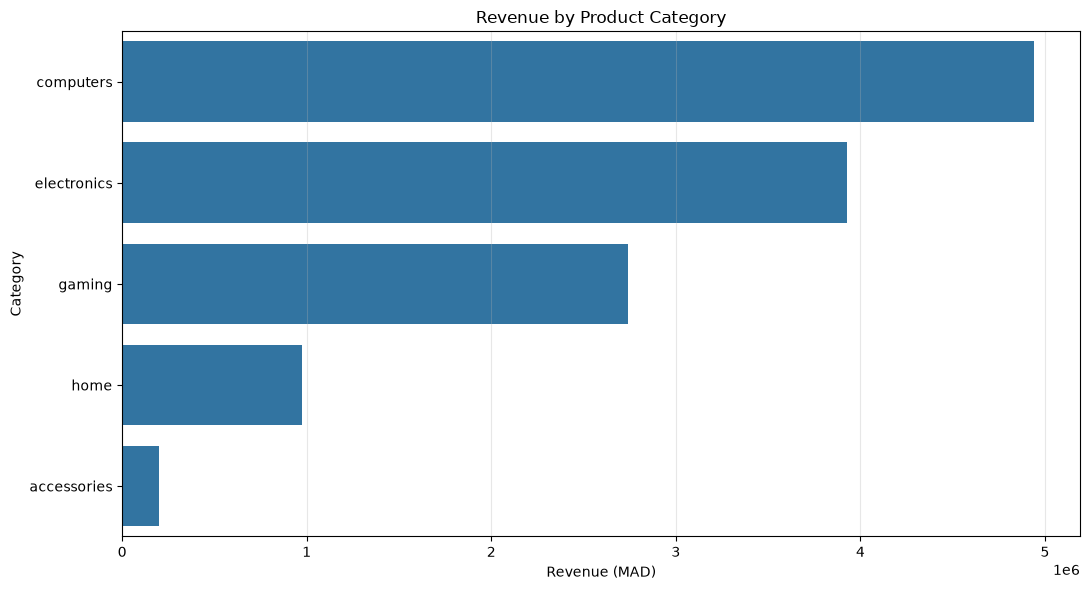

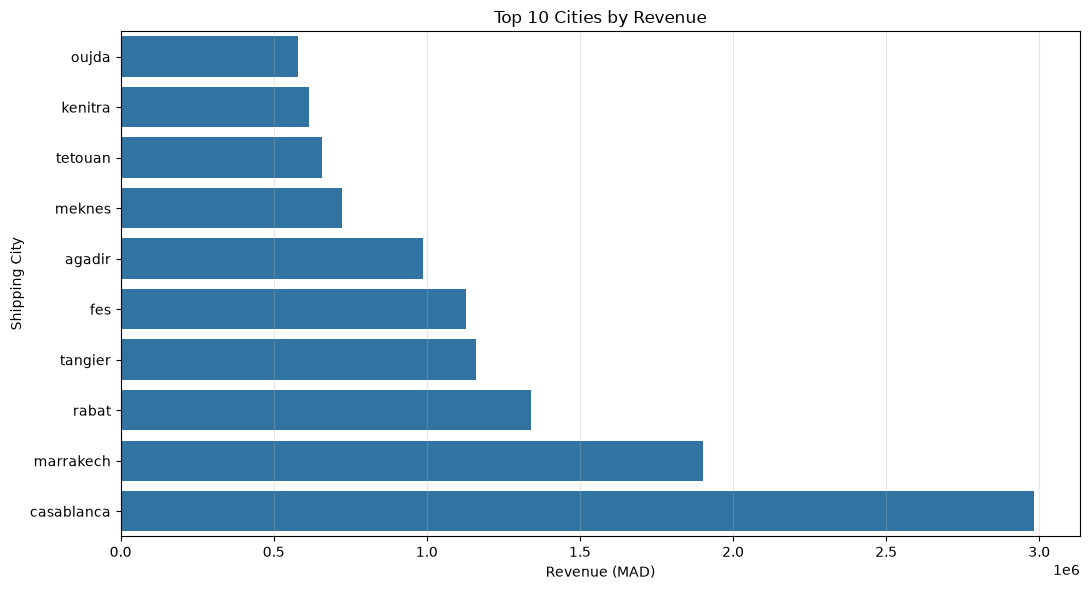

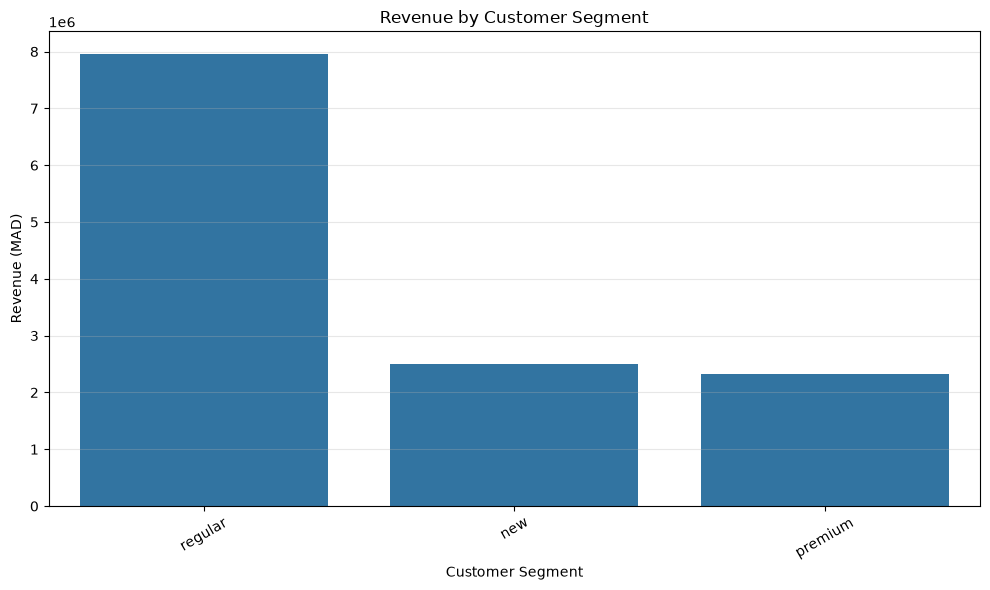

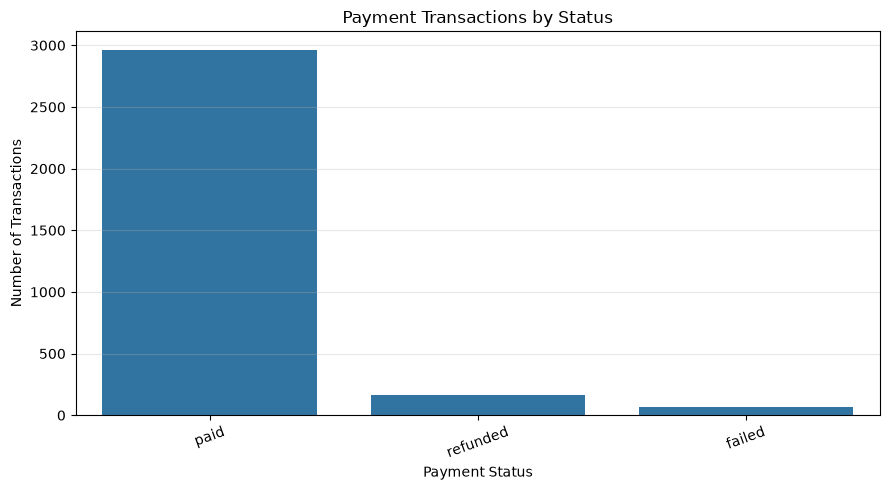

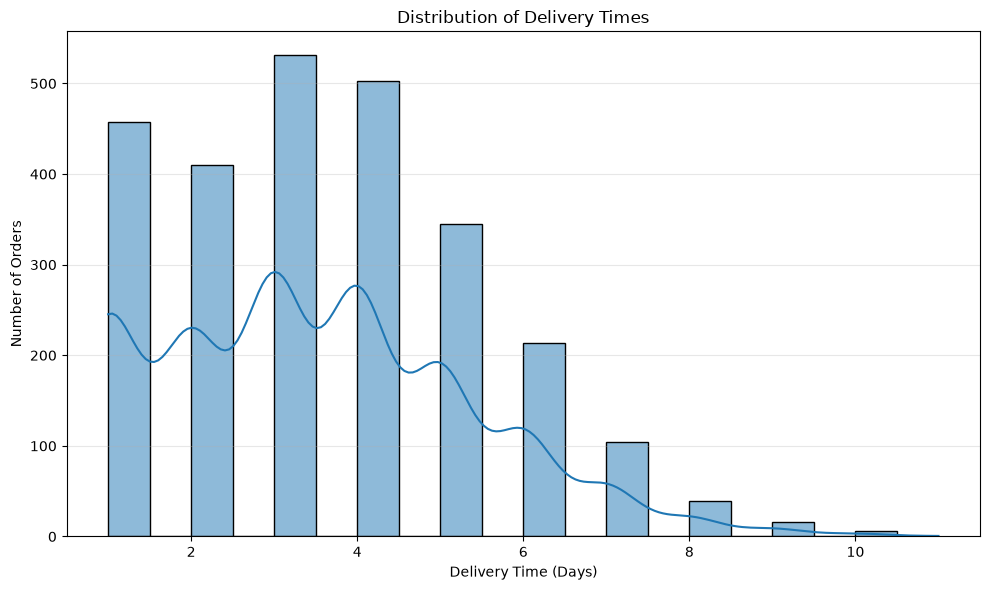

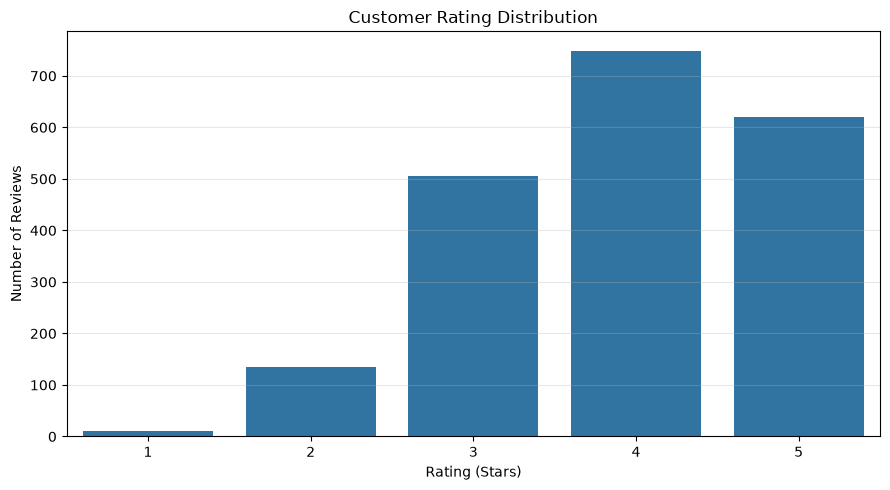

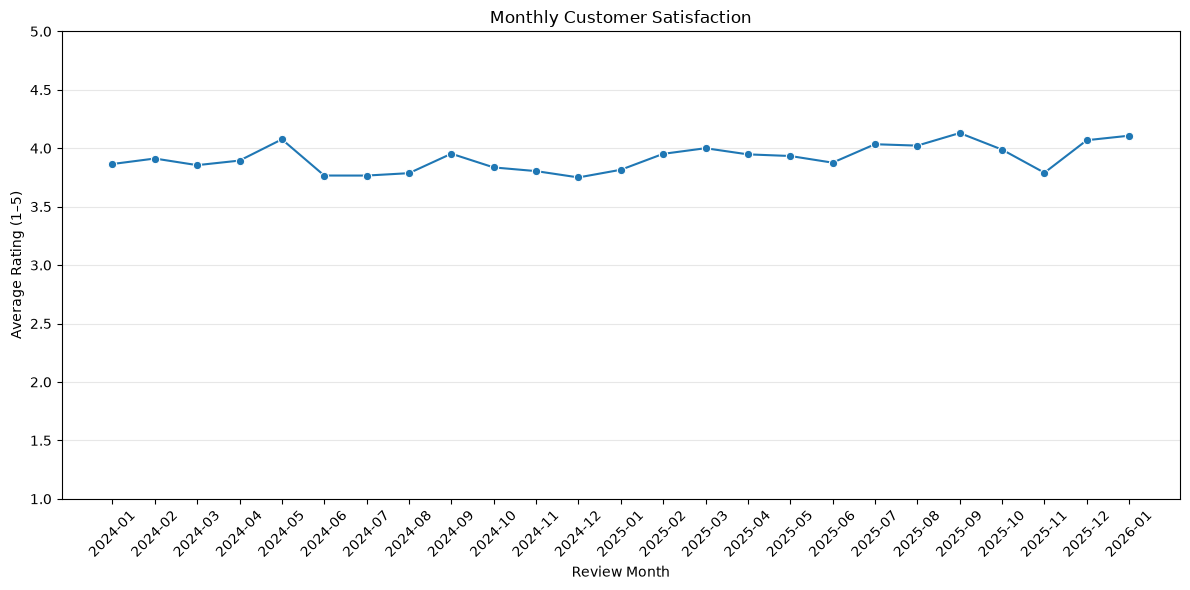

In [59]:
# 1. Monthly revenue
plot_monthly_revenue(
    monthly_sales,
    FIGURES_DIR,
)

# 2. Product category revenue
plot_category_revenue(
    category_performance,
    FIGURES_DIR,
)

# 3. Top cities
plot_top_cities(
    city_performance,
    FIGURES_DIR,
    top_n=10,
)

# 4. Customer segment performance
plot_customer_segments(
    segment_performance,
    FIGURES_DIR,
)

# 5. Payment outcomes
plot_payment_status(
    payment_status,
    FIGURES_DIR,
)

# 6. Delivery time distribution
plot_delivery_distribution(
    delivery_data,
    FIGURES_DIR,
)

# 7. Customer rating distribution
plot_rating_distribution(
    rating_distribution,
    FIGURES_DIR,
)

# 8. Monthly customer satisfaction
plot_monthly_satisfaction(
    monthly_satisfaction,
    FIGURES_DIR,
)